# Clase 3 - BER de LoRa en canal selectivo

**Objetivo.** Partir de un chirp LoRa ideal, aplicarle el canal selectivo del artículo y medir cómo el ruido afecta la BER. Las funciones de procesamiento por lotes se escriben aquí —en lugar de ocultarlas en `src`— para que cada paso de la simulación pueda leerse y relacionarse con su ecuación. Los símbolos y el ruido se generan sin semilla fija, por lo que cada ejecución produce una realización distinta.

In [11]:
from pathlib import Path
import sys

from matplotlib.axes import Axes
import matplotlib.pyplot as plt
import numpy as np

raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.lora_chirp import (
    agregar_ruido_awgn,
    calc_error,
    demodular_simbolo,
    modular_simbolo,
    parametros_ruido_desde_snr,
)


## 1. Repaso: un símbolo ideal

**Objetivo.** Verificar el caso base antes de introducir canal y ruido. Con `SF=7`, cada símbolo representa 7 bits y tiene `N=128` muestras. Modulamos un entero, aplicamos dechirp y FFT, y comprobamos que el símbolo detectado y la BER sean correctos en el canal ideal.

In [12]:
SF = 7
N = 2**SF
B = 125_000  # Hz
Ts = N / B
generador_repaso = np.random.default_rng()

enviado = int(generador_repaso.integers(N))
chirp = modular_simbolo(enviado, np.arange(N), N)
estimado, _, espectro_ideal = demodular_simbolo(chirp)
ber_ideal = calc_error([enviado], [estimado], bits_por_simbolo=SF)

assert estimado == enviado and ber_ideal == 0
print(f'SF={SF}, N={N}, Ts={Ts * 1e3:.3f} ms')
print(f'Enviado: {enviado:0{SF}b}; detectado: {estimado:0{SF}b}; BER={ber_ideal:.1f}')


SF=7, N=128, Ts=1.024 ms
Enviado: 1111001; detectado: 1111001; BER=0.0


## 2. Chirp discreto y modelo teórico suavizado

**Objetivo.** Distinguir la señal discreta que usa el receptor de su representación teórica continua y conectarla con la decisión del demodulador. El primer panel contiene las `N` muestras reales; los dos siguientes evalúan la misma ecuación con más instantes para leer mejor la forma de la señal y su frecuencia instantánea. El último panel muestra la energía después de dechirp y FFT: su máximo indica el símbolo detectado. La curva suavizada explica la sierra, pero no agrega muestras a la transmisión.

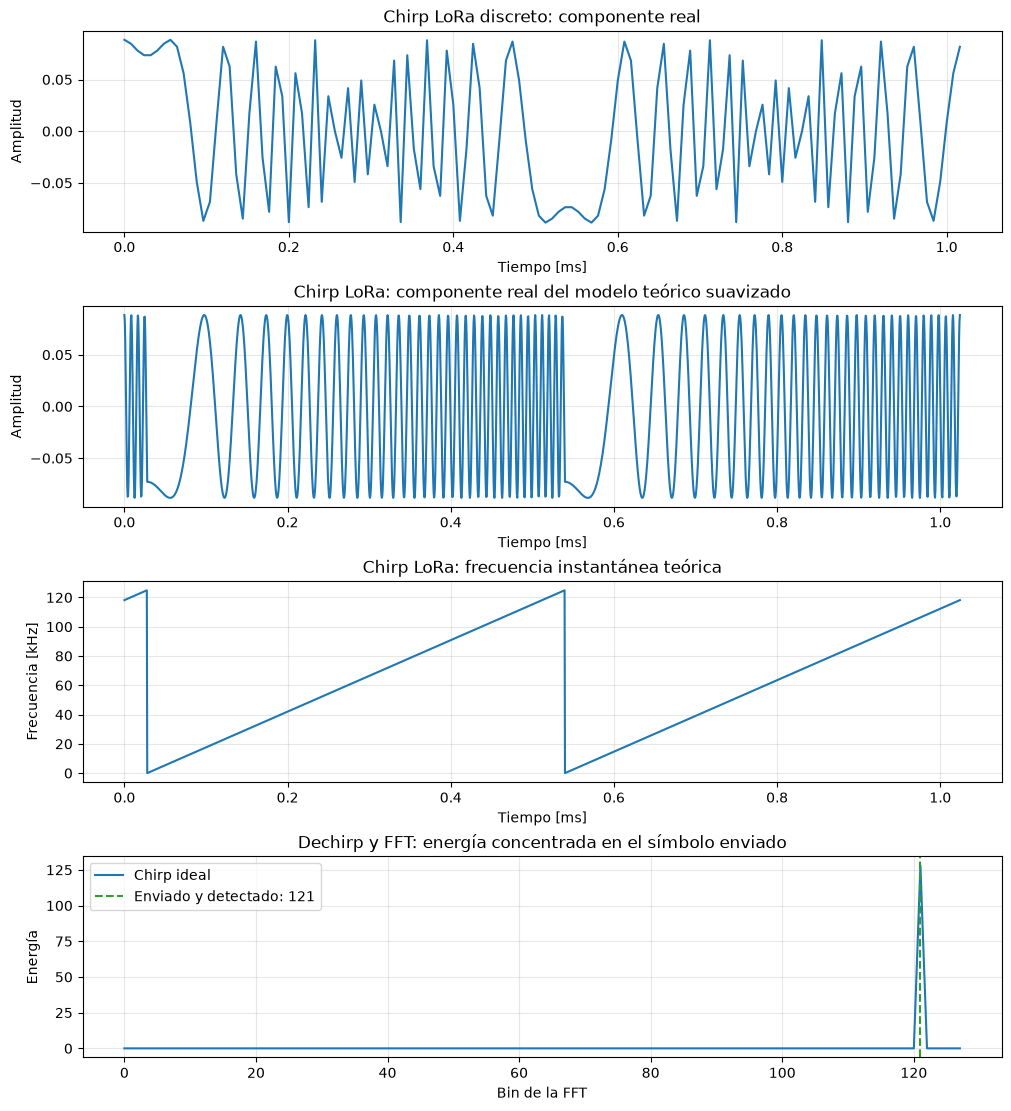

In [13]:
def graficar_curvas(
    tiempo: np.ndarray,
    curvas: list[tuple[str, np.ndarray]],
    *,
    titulo: str,
    etiqueta_y: str,
    ax: Axes | None = None,
) -> Axes:
    """Grafica curvas temporales con el formato común de este notebook."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
    for etiqueta, valores in curvas:
        ax.plot(tiempo * 1e3, valores, label=etiqueta)
    ax.set(title=titulo, xlabel='Tiempo [ms]', ylabel=etiqueta_y)
    ax.grid(True, alpha=0.3)
    if len(curvas) > 1:
        ax.legend()
    return ax

def graficar_energia_espectral(
    espectros: list[tuple[str, np.ndarray]],
    *, enviado: int, detectado: int, titulo: str, ax: Axes
) -> Axes:
    """Muestra la energía de la FFT y los bins relevantes para decidir."""
    bins = np.arange(N)
    for etiqueta, espectro in espectros:
        ax.plot(bins, np.abs(espectro)**2, label=etiqueta)
    if enviado == detectado:
        ax.axvline(enviado, color='tab:green', linestyle='--', label=f'Enviado y detectado: {enviado}')
    else:
        ax.axvline(enviado, color='tab:green', linestyle='--', label=f'Enviado: {enviado}')
        ax.axvline(detectado, color='tab:red', linestyle=':', label=f'Detectado: {detectado}')
    ax.set(title=titulo, xlabel='Bin de la FFT', ylabel='Energía')
    ax.grid(True, alpha=0.3)
    ax.legend()
    return ax

def fase_sierra(tiempo: np.ndarray, valor: int) -> np.ndarray:
    # Integra la frecuencia de la sierra para obtener fase continua, en ciclos.
    indice = valor + 2 * B * tiempo
    ciclos_completos = np.floor(indice / N)
    resto = np.mod(indice, N)
    area = (ciclos_completos * N**2 + resto**2) / 2
    return (area - valor**2 / 2) / (2 * N)

def chirp_teorico(tiempo: np.ndarray, valor: int) -> np.ndarray:
    """Extensión continua del chirp discreto; se usa sólo para visualizar."""
    return np.exp(1j * 2 * np.pi * fase_sierra(tiempo, valor)) / np.sqrt(N)

def vista_teorica(valor: int, muestras_por_muestra: int = 16):
    tiempo = np.linspace(0, Ts, N * muestras_por_muestra + 1)
    senal = chirp_teorico(tiempo, valor)
    frecuencia = np.mod(valor + 2 * B * tiempo, N) * B / N
    return tiempo, senal, frecuencia

k = np.arange(N)
tiempo_discreto = k / B
tiempo_suave, chirp_suave, frecuencia_suave = vista_teorica(enviado)

fig, axes = plt.subplots(4, 1, figsize=(10, 11), constrained_layout=True)
graficar_curvas(
    tiempo_discreto, [('Muestras del chirp', chirp.real)],
    titulo='Chirp LoRa discreto: componente real', etiqueta_y='Amplitud', ax=axes[0]
)
graficar_curvas(
    tiempo_suave, [('Modelo teórico', chirp_suave.real)],
    titulo='Chirp LoRa: componente real del modelo teórico suavizado', etiqueta_y='Amplitud', ax=axes[1]
)
graficar_curvas(
    tiempo_suave, [('Frecuencia instantánea', frecuencia_suave / 1e3)],
    titulo='Chirp LoRa: frecuencia instantánea teórica', etiqueta_y='Frecuencia [kHz]', ax=axes[2]
)
graficar_energia_espectral(
    [('Chirp ideal', espectro_ideal)], enviado=enviado, detectado=estimado,
    titulo='Dechirp y FFT: energía concentrada en el símbolo enviado', ax=axes[3]
)
plt.show()


## 3. Canal FIR y procesamiento por lotes

**Objetivo.** Construir el canal selectivo y el único motor reutilizable de simulación. En esta primera celda se definen y verifican las herramientas: el FIR, la modulación y detección por lotes, y `simular_lote`. Las partes 4, 5 y 6 sólo cambiarán cuántos símbolos le piden a ese motor. El siguiente bloque usa esas herramientas para visualizar qué hace el FIR sobre un chirp.

In [14]:
def aplicar_canal_fir(senal: np.ndarray, respuesta_impulsional: np.ndarray) -> np.ndarray:
    # y[k] = sum_m h[m] x[k-m]; np.convolve devuelve también la cola del filtro.
    return np.convolve(senal, respuesta_impulsional)

def modular_trama(valores: np.ndarray) -> np.ndarray:
    # Cada fila corresponde a un símbolo; el broadcasting evalúa todos los chirps juntos.
    k = np.arange(N)
    fase = ((valores[:, None] + k) % N) * k / N
    return np.exp(1j * 2 * np.pi * fase) / np.sqrt(N)

def demodular_trama(recibidas: np.ndarray) -> np.ndarray:
    # El mismo downchirp se multiplica por cada fila y la FFT se calcula sobre axis=1.
    k = np.arange(N)
    downchirp = np.exp(-1j * 2 * np.pi * k**2 / N)
    espectros = np.fft.fft(recibidas * downchirp, axis=1)
    return np.argmax(np.abs(espectros)**2, axis=1)

# Canal del artículo: su energía es uno, así que no amplifica la señal en promedio.
h = np.array([np.sqrt(0.8), np.sqrt(0.2)])
assert np.isclose(np.sum(np.abs(h)**2), 1.0)
impulso = np.r_[1.0, np.zeros(N - 1)]
np.testing.assert_allclose(aplicar_canal_fir(impulso, h)[:len(h)], h)

def simular_lote(
    snr_db: float,
    cantidad_simbolos: int,
    generador: np.random.Generator,
    respuesta_impulsional: np.ndarray = h,
    retardo_canal: int = 0,
):
    """Simula símbolos aleatorios: chirp, FIR, AWGN y detección."""
    enviados = generador.integers(0, N, cantidad_simbolos)
    transmitida = modular_trama(enviados)
    # Se concatena la trama para que la memoria del FIR pase de un símbolo al siguiente.
    salida_completa = aplicar_canal_fir(transmitida.ravel(), respuesta_impulsional)
    # Un delta centrado sólo retrasa; se alinea antes de separar nuevamente los símbolos.
    filtrada = salida_completa[retardo_canal:retardo_canal + transmitida.size]
    limpia = filtrada.reshape(cantidad_simbolos, N)
    potencia_senal = float(np.mean(np.abs(transmitida)**2))
    _, sigma = parametros_ruido_desde_snr(snr_db, potencia_senal)
    # El ruido se suma después del FIR para conservar AWGN blanco en el receptor.
    recibida, ruido = agregar_ruido_awgn(limpia, sigma, generador)
    estimados = demodular_trama(recibida)
    return enviados, estimados, limpia, recibida, ruido, potencia_senal, sigma

# Control sin ruido: el mismo motor conserva todos los símbolos del alfabeto.
control = np.arange(N)
control_limpio = aplicar_canal_fir(modular_trama(control).ravel(), h)[:N*N].reshape(N, N)
assert calc_error(control, demodular_trama(control_limpio), bits_por_simbolo=SF) == 0




### 3.1 Visualizar el efecto del canal

**Objetivo.** Usar las herramientas anteriores para observar el FIR sin mezclar esta demostración con su definición. El primer panel es la respuesta impulsional $h[k]$; el segundo compara la parte real suavizada antes y después del filtro; el tercero muestra la energía de la señal discreta tras dechirp y FFT. El cálculo del canal que se detecta sigue siendo la convolución discreta.

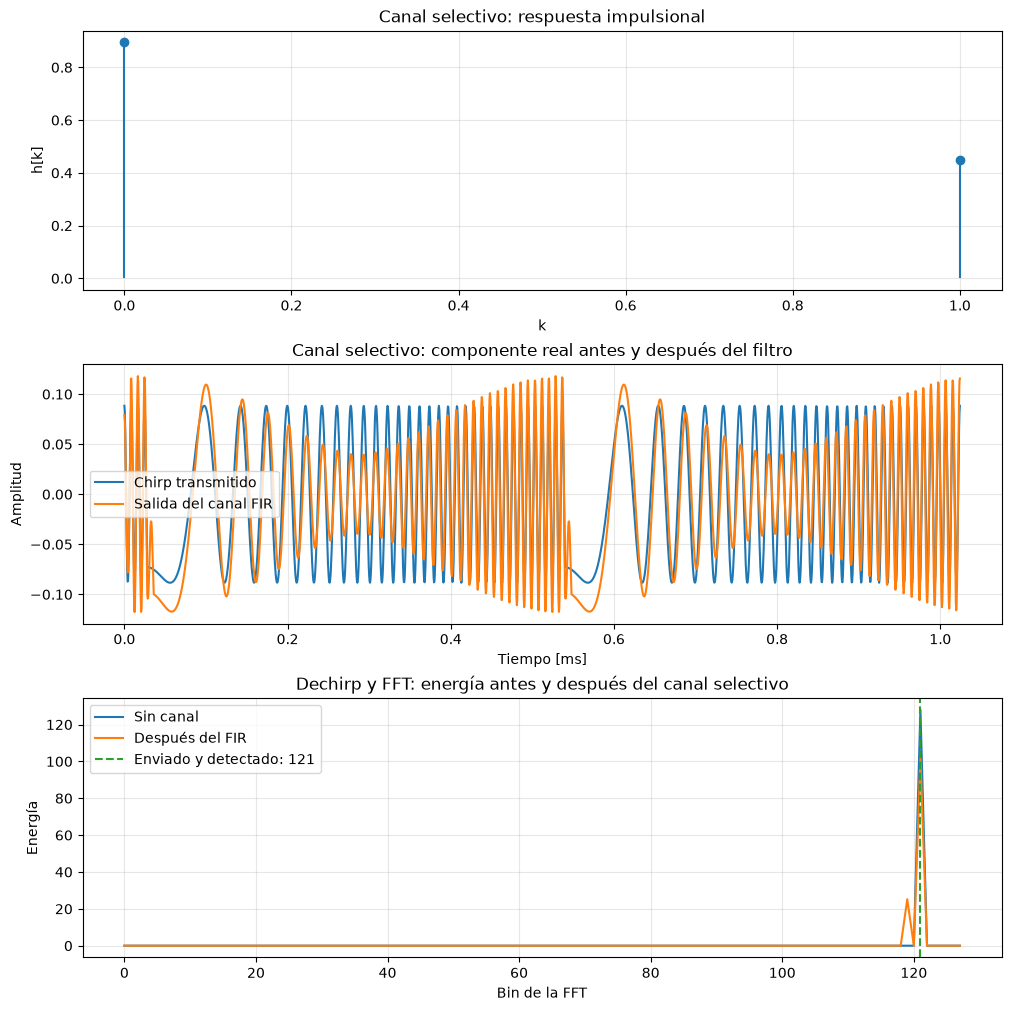

In [15]:
# Extensión continua sólo para el segundo panel: un retardo equivale a una muestra Tm=1/B.
retardo_muestra = 1 / B
chirp_retrasado = chirp_teorico(tiempo_suave - retardo_muestra, enviado)
chirp_retrasado[tiempo_suave < retardo_muestra] = 0
salida_suave = h[0] * chirp_suave + h[1] * chirp_retrasado

# Esta es la convolución discreta que recibe y demodula el receptor.
salida_discreta = aplicar_canal_fir(chirp, h)[:N]
detectado_canal, _, espectro_canal = demodular_simbolo(salida_discreta)
_, _, espectro_sin_canal = demodular_simbolo(chirp)
assert detectado_canal == enviado

fig, axes = plt.subplots(3, 1, figsize=(10, 10), constrained_layout=True)
axes[0].stem(np.arange(len(h)), h, basefmt=' ')
axes[0].set(title='Canal selectivo: respuesta impulsional', xlabel='k', ylabel='h[k]')
axes[0].grid(True, alpha=0.3)
graficar_curvas(
    tiempo_suave,
    [('Chirp transmitido', chirp_suave.real), ('Salida del canal FIR', salida_suave.real)],
    titulo='Canal selectivo: componente real antes y después del filtro',
    etiqueta_y='Amplitud', ax=axes[1]
)
graficar_energia_espectral(
    [('Sin canal', espectro_sin_canal), ('Después del FIR', espectro_canal)],
    enviado=enviado, detectado=detectado_canal,
    titulo='Dechirp y FFT: energía antes y después del canal selectivo', ax=axes[2]
)
plt.show()


## 4. ¿Dónde se agrega el ruido?

**Objetivo.** Mostrar el orden físico del canal y una realización que produce un error. Primero se calcula $y=c*h$ mediante convolución y luego se suma AWGN: $r=y+w$. Así el ruido es blanco en la entrada del receptor; si se agregara antes, el FIR lo colorearía y sería otro canal. Buscamos una realización con error: el panel superior muestra sus muestras reales y el inferior compara las energías de las FFT luego de dechirp. Las líneas verticales indican el bin enviado y el que ganó la detección.

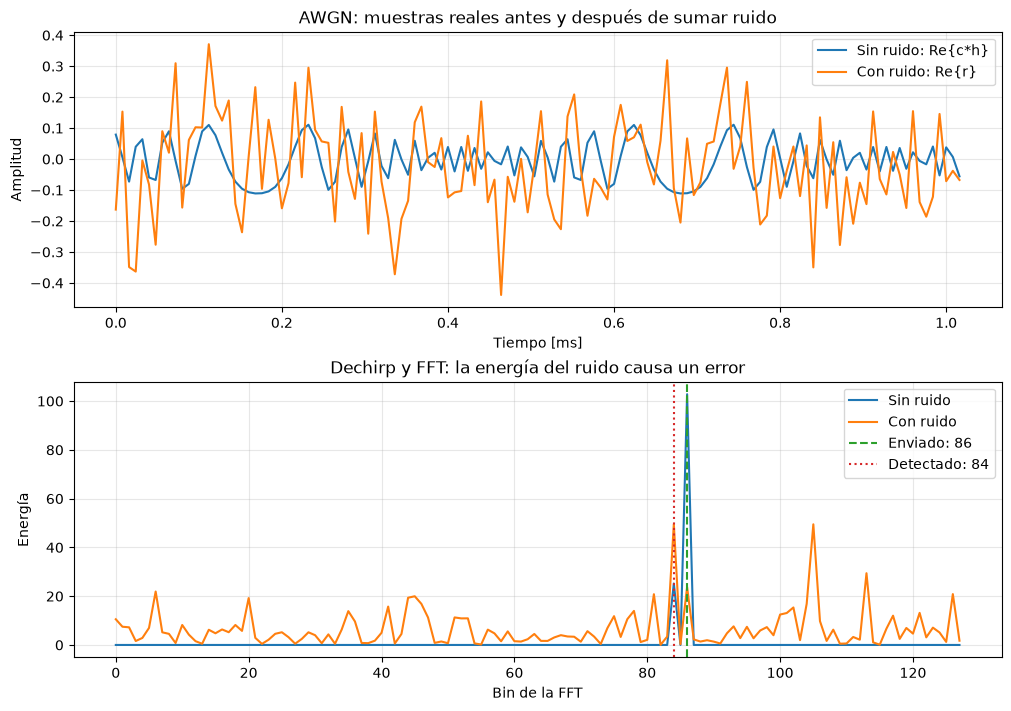

SNR=-7 dB | enviado=1010110 | detectado=1010100


In [16]:
generador_error = np.random.default_rng()
SNR_ERROR_DB = -7
for _ in range(500):
    enviados_error, estimados_error, limpias, recibidas, _, _, _ = simular_lote(
        SNR_ERROR_DB, 1, generador_error
    )
    valor_error = int(enviados_error[0])
    detectado_error = int(estimados_error[0])
    if detectado_error != valor_error: # encontré un error
        limpia, ruidosa = limpias[0], recibidas[0]
        break
else:
    raise RuntimeError('No se encontró un error; probá una SNR menor')

_, _, espectro_limpio = demodular_simbolo(limpia)
_, _, espectro_ruidoso = demodular_simbolo(ruidosa)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)
graficar_curvas(
    tiempo_discreto,
    [('Sin ruido: Re{c*h}', limpia.real), ('Con ruido: Re{r}', ruidosa.real)],
    titulo='AWGN: muestras reales antes y después de sumar ruido',
    etiqueta_y='Amplitud', ax=axes[0]
)
graficar_energia_espectral(
    [('Sin ruido', espectro_limpio), ('Con ruido', espectro_ruidoso)],
    enviado=valor_error, detectado=detectado_error,
    titulo='Dechirp y FFT: la energía del ruido causa un error', ax=axes[1]
)
plt.show()
print(f'SNR={SNR_ERROR_DB} dB | enviado={valor_error:0{SF}b} | detectado={detectado_error:0{SF}b}')


## 5. BER en una SNR

**Objetivo.** Obtener una estimación puntual de BER antes del barrido. Reutilizamos `simular_lote` con 10.000 símbolos aleatorios: no se crea otro canal ni otra cadena de recepción. `calc_error(..., bits_por_simbolo=SF)` compara los 7 bits de cada entero sin convertir miles de símbolos a texto. Aquí alcanza con reportar potencia, errores y BER; la visualización de un error ya quedó explicada en la parte 4.

In [17]:
SNR_EJEMPLO_DB = -15
generador_ejemplo = np.random.default_rng()
enviados, estimados, _, _, ruido, potencia_senal, sigma = simular_lote(
    SNR_EJEMPLO_DB, 10_000, generador_ejemplo
)
ber_ejemplo = calc_error(enviados, estimados, bits_por_simbolo=SF)
bits_comparados = len(enviados) * SF
errores = round(ber_ejemplo * bits_comparados)
print(f'SNR={SNR_EJEMPLO_DB} dB | BER={ber_ejemplo:.3e} ({errores} errores sobre {bits_comparados} bits)')
print(f'Potencia señal={potencia_senal:.6f}; potencia ruido medida={np.mean(np.abs(ruido)**2):.6f}; sigma={sigma:.6f}')


SNR=-15 dB | BER=3.414e-01 (23898 errores sobre 70000 bits)
Potencia señal=0.007812; potencia ruido medida=0.247082; sigma=0.497044


## 6. Curva BER Monte Carlo

**Objetivo.** Repetir la medición de la parte 5 para cada SNR entre −9 y −3 dB. `estimar_ber` no crea otro modelo: llama varias veces a `simular_lote` hasta acumular 100 errores de bit o alcanzar 250.000 símbolos. El segundo límite evita que la simulación se vuelva innecesariamente lenta cuando la BER es muy baja; por eso cada fila reporta símbolos, bits y errores junto a su BER. Como los símbolos y el ruido son nuevos en cada ejecución, la curva tendrá pequeñas variaciones estadísticas. La comparación con el canal plano se grafica al final, en la parte 7.

In [18]:
def estimar_ber(
    snr_db: float,
    respuesta_impulsional: np.ndarray = h,
    retardo_canal: int = 0,
) -> tuple[int, int, int, float]:
    generador = np.random.default_rng()
    errores_totales = bits_totales = simbolos_totales = 0
    while errores_totales < 100 and simbolos_totales < 250_000:
        cantidad = min(10_000, 250_000 - simbolos_totales)
        enviados, estimados, _, _, _, _, _ = simular_lote(
            snr_db, cantidad, generador, respuesta_impulsional, retardo_canal
        )
        ber_lote = calc_error(enviados, estimados, bits_por_simbolo=SF)
        bits_lote = cantidad * SF
        # BER por cantidad de bits recupera el entero de errores de este lote.
        errores_totales += round(ber_lote * bits_lote)
        bits_totales += bits_lote
        simbolos_totales += cantidad
    return simbolos_totales, bits_totales, errores_totales, errores_totales / bits_totales

snr_db = np.arange(-9, -2, 1)
resultados = [estimar_ber(snr) for snr in snr_db]
ber = np.array([resultado[-1] for resultado in resultados])
for snr, (simbolos, bits, errores, valor_ber) in zip(snr_db, resultados):
    print(f'SNR={snr:>3} dB | símbolos={simbolos:>6} | bits={bits:>7} | errores={errores:>4} | BER={valor_ber:.3e}')



SNR= -9 dB | símbolos= 10000 | bits=  70000 | errores=1584 | BER=2.263e-02
SNR= -8 dB | símbolos= 10000 | bits=  70000 | errores= 663 | BER=9.471e-03
SNR= -7 dB | símbolos= 10000 | bits=  70000 | errores= 295 | BER=4.214e-03
SNR= -6 dB | símbolos= 10000 | bits=  70000 | errores= 113 | BER=1.614e-03
SNR= -5 dB | símbolos= 30000 | bits= 210000 | errores= 127 | BER=6.048e-04
SNR= -4 dB | símbolos= 60000 | bits= 420000 | errores= 111 | BER=2.643e-04
SNR= -3 dB | símbolos=250000 | bits=1750000 | errores=  72 | BER=4.114e-05


## 7. Curva BER Monte Carlo: comparación con canal plano

**Objetivo.** Repetir el barrido con un canal plano y compararlo en la misma figura con el canal selectivo. Su respuesta impulsional es un impulso unitario centrado, $h_{\mathrm{plano}}[k]=\delta[k-1]=[0,1,0]$: sólo retrasa la señal una muestra y no altera su amplitud ni su frecuencia. Para separar este retardo de la distorsión del canal, `simular_lote` lo alinea antes de demodular. El canal plano se barre desde −12 dB para apreciar su zona de BER alta. Si un punto no observa errores, se informa BER cero en la tabla y se omite del gráfico, porque la escala logarítmica no puede representar cero.

SNR=-12 dB | símbolos= 10000 | bits=  70000 | errores=7081 | BER=1.012e-01
SNR=-11 dB | símbolos= 10000 | bits=  70000 | errores=3517 | BER=5.024e-02
SNR=-10 dB | símbolos= 10000 | bits=  70000 | errores=1225 | BER=1.750e-02
SNR= -9 dB | símbolos= 10000 | bits=  70000 | errores= 362 | BER=5.171e-03
SNR= -8 dB | símbolos= 20000 | bits= 140000 | errores= 137 | BER=9.786e-04
SNR= -7 dB | símbolos=100000 | bits= 700000 | errores= 111 | BER=1.586e-04
SNR= -6 dB | símbolos=250000 | bits=1750000 | errores=   7 | BER=4.000e-06
SNR= -5 dB | símbolos=250000 | bits=1750000 | errores=   0 | BER=0.000e+00
SNR= -4 dB | símbolos=250000 | bits=1750000 | errores=   0 | BER=0.000e+00
SNR= -3 dB | símbolos=250000 | bits=1750000 | errores=   0 | BER=0.000e+00


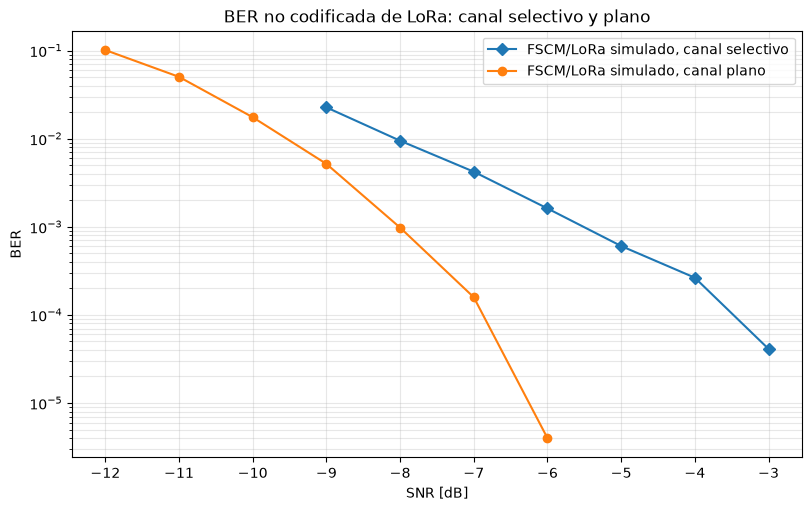

In [19]:
# Impulso unitario centrado: canal plano con un retardo de una muestra.
h_plano = np.array([0.0, 1.0, 0.0])
retardo_plano = len(h_plano) // 2
assert np.isclose(np.sum(np.abs(h_plano)**2), 1.0)

# Sin ruido y con el retardo alineado, el canal plano no cambia ningún símbolo.
control_transmitida = modular_trama(control).ravel()
control_plano = aplicar_canal_fir(control_transmitida, h_plano)
control_plano = control_plano[retardo_plano:retardo_plano + control_transmitida.size]
control_plano = control_plano.reshape(N, N)
assert calc_error(control, demodular_trama(control_plano), bits_por_simbolo=SF) == 0

snr_db_plano = np.arange(-12, -2, 1)
resultados_plano = [
    estimar_ber(snr, h_plano, retardo_plano) for snr in snr_db_plano
]
ber_plano = np.array([resultado[-1] for resultado in resultados_plano])
for snr, (simbolos, bits, errores, valor_ber) in zip(snr_db_plano, resultados_plano):
    print(f'SNR={snr:>3} dB | símbolos={simbolos:>6} | bits={bits:>7} | errores={errores:>4} | BER={valor_ber:.3e}')

# Logaritmo de cero no existe: esos puntos se informan en la tabla, no se dibujan.
mascara_plano = ber_plano > 0
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.semilogy(snr_db, ber, 'D-', label='FSCM/LoRa simulado, canal selectivo')
ax.semilogy(
    snr_db_plano[mascara_plano], ber_plano[mascara_plano], 'o-',
    label='FSCM/LoRa simulado, canal plano',
)
ax.set(title='BER no codificada de LoRa: canal selectivo y plano', xlabel='SNR [dB]', ylabel='BER')
ax.set_xticks(np.arange(-12, -2, 1))
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.show()


## Conclusión

La simulación discreta sigue siempre la cadena `símbolo → chirp → convolución FIR → AWGN → dechirp/FFT → BER`. Las curvas finales reutilizan esa misma cadena: una usa el canal selectivo del artículo y la otra el impulso unitario del canal plano. La única curva suavizada es el modelo teórico de las secciones 2 y 3; las comparaciones con ruido muestran sus muestras reales para no ocultar su naturaleza aleatoria.